# Chapitre 2 - Cours 3 : Le post-entraînement (SFT, préférences, RLHF)

Un modèle pré-entraîné sait beaucoup de choses mais se comporte comme une page web, pas
comme un assistant : il **complète** du texte, et reproduit sans filtre ce qu'il a lu.
Le post-entraînement corrige ces deux défauts. Ce notebook couvre la section
*Post-Training* du livre :

- *Supervised Finetuning* : apprendre à converser à partir de démonstrations ;
- *Preference Finetuning* : données de comparaison, *Reward model* (que l'on implémente
  sur un jouet avec la perte de Bradley-Terry), *Finetuning using the reward model*
  (RLHF, et son cousin DPO) ;
- la stratégie *best of N*, qui utilise le modèle de récompense sans apprentissage par
  renforcement.

**Plan.** 1. Pourquoi post-entraîner ? 2. Le finetuning supervisé ; 3. Données de
préférence : comparer plutôt que noter ; 4. Le modèle de récompense de Bradley-Terry ;
5. Optimiser contre la récompense : RLHF et DPO ; 6. Best-of-N et sur-optimisation ;
Synthèse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import kendalltau

from aie import llm
from aie import ch02_modeles as m
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.max_colwidth", 120)
BASE_QWEN = "Qwen/Qwen2.5-0.5B"          # modèle pré-entraîné (de base)
INSTRUCT_QWEN = llm.SMALL                # même modèle après post-entraînement (SFT + préférences)


def short(txt, n=260):
    txt = " ".join(txt.split())
    return txt if len(txt) <= n else txt[:n] + " [...]"

## 1. Pourquoi post-entraîner ? (section *Post-Training*)

Le pré-entraînement auto-supervisé produit un modèle qui a deux défauts : il est optimisé
pour **compléter** du texte, pas pour converser, et, entraîné sur un web non filtré, il
peut être raciste, sexiste, grossier ou simplement faux. Le post-entraînement procède en
général en deux étapes :

1. le **finetuning supervisé** (SFT) sur des données d'instruction de qualité, pour
   passer de la complétion à la conversation ;
2. le **finetuning sur préférences**, pour aligner les réponses sur les préférences
   humaines, le plus souvent par apprentissage par renforcement : RLHF (GPT-3.5,
   Llama 2), DPO (Llama 3), RLAIF (retours d'IA plutôt qu'humains).

Autre façon de le dire : le pré-entraînement optimise la qualité **au niveau du token**
(prédire le suivant), alors que les utilisateurs jugent la qualité de la **réponse
entière**. Le post-entraînement est peu coûteux : 2 % du calcul pour InstructGPT, contre
98 % pour le pré-entraînement. Il **débloque** des capacités déjà présentes plutôt qu'il
n'en crée.

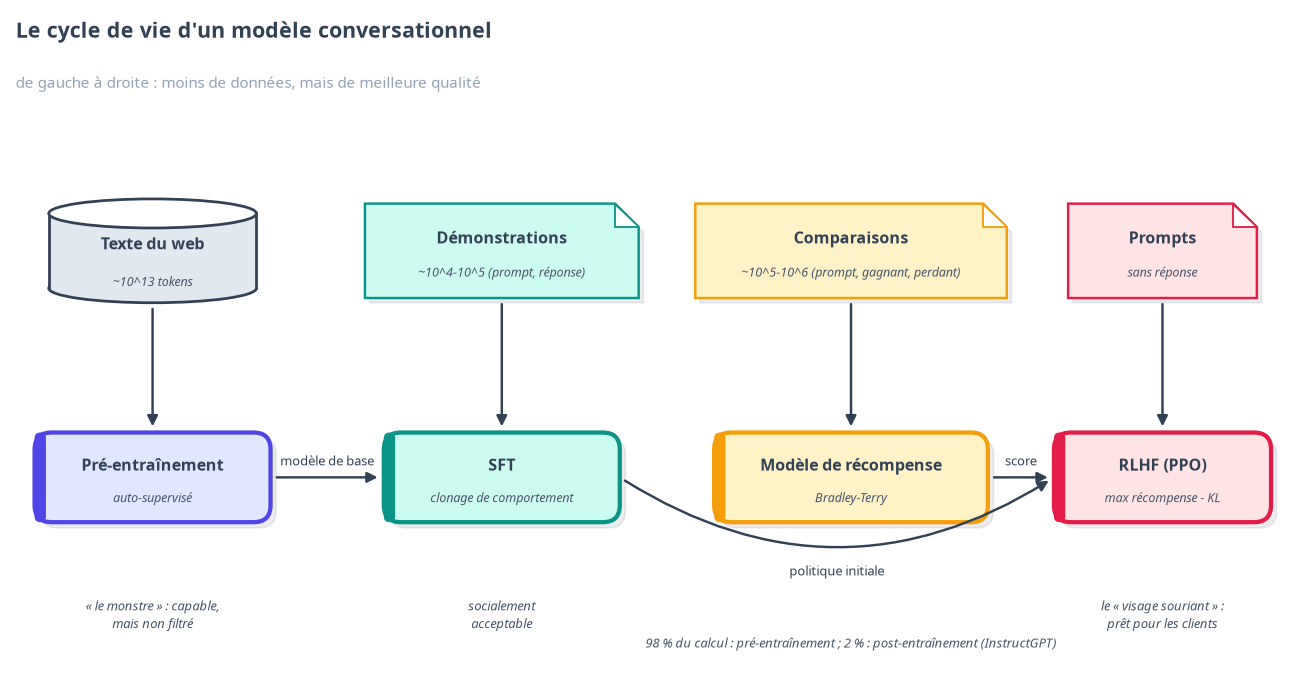

In [2]:
d = Diagram(13.5, 6.2, title="Le cycle de vie d'un modèle conversationnel",
            subtitle="de gauche à droite : moins de données, mais de meilleure qualité")
# lignes de données
d.box("web", 1.5, 4.6, "Texte du web", sub="~10^13 tokens", color=SLATE, kind="db", w=2.2, h=1.1)
d.box("demo", 5.2, 4.6, "Démonstrations", sub="~10^4-10^5 (prompt, réponse)", color=TEAL, kind="doc", w=2.9, h=1.0)
d.box("comp", 8.9, 4.6, "Comparaisons", sub="~10^5-10^6 (prompt, gagnant, perdant)", color=AMBER, kind="doc",
      w=3.3, h=1.0)
d.box("prompts", 12.2, 4.6, "Prompts", sub="sans réponse", color=ROSE, kind="doc", w=2.0, h=1.0)
# modèles
d.box("pt", 1.5, 2.2, "Pré-entraînement", sub="auto-supervisé", color=INDIGO, kind="model", w=2.5, h=0.95)
d.box("sft", 5.2, 2.2, "SFT", sub="clonage de comportement", color=TEAL, kind="model", w=2.5, h=0.95)
d.box("rm", 8.9, 2.2, "Modèle de récompense", sub="Bradley-Terry", color=AMBER, kind="model", w=2.9, h=0.95)
d.box("rl", 12.2, 2.2, "RLHF (PPO)", sub="max récompense - KL", color=ROSE, kind="model", w=2.3, h=0.95)
for a, b in [("web", "pt"), ("demo", "sft"), ("comp", "rm"), ("prompts", "rl")]:
    d.arrow(a, b)
d.arrow("pt", "sft", "modèle de base")
d.arrow("sft", "rl", "politique initiale", rad=0.32, label_offset=(0, -0.25))
d.arrow("rm", "rl", "score")
d.note(1.5, 0.75, "« le monstre » : capable,\nmais non filtré", fontsize=8.5)
d.note(5.2, 0.75, "socialement\nacceptable", fontsize=8.5)
d.note(12.2, 0.75, "le « visage souriant » :\nprêt pour les clients", fontsize=8.5)
d.note(8.9, 0.45, "98 % du calcul : pré-entraînement ; 2 % : post-entraînement (InstructGPT)", fontsize=8.5)
d.show()

Le livre compare ce schéma au mème du Shoggoth au visage souriant : un monstre
(pré-entraînement), rendu fréquentable par le SFT, puis poli par le finetuning sur
préférences. Aucune étape n'est obligatoire.

**Observons la différence.** Qwen2.5-0.5B existe en deux versions : le modèle **de base**
(pré-entraîné) et la version **Instruct** (post-entraînée). Donnons à chacune la même
demande, en texte brut au modèle de base (complétion), via le gabarit de conversation au
modèle Instruct.

In [3]:
demandes = ["How to make pizza", "Explique en une phrase ce qu'est un trou noir."]
rows = []
for q in demandes:
    base_out = llm.complete(q, model_id=BASE_QWEN, max_new_tokens=60)
    inst_out = llm.chat(q, model_id=INSTRUCT_QWEN, max_new_tokens=60)
    rows.append({"demande": q, "modèle de base (complétion)": short(base_out, 200),
                 "modèle Instruct (conversation)": short(inst_out, 200)})
pd.DataFrame(rows)

,demande,modèle de base (complétion),modèle Instruct (conversation)
0,How to make pizza,"<br>Preheat the oven to 425 degrees fahrenheit (220 degrees celsius). If you're making a large pizza, preheat the ov...",Making pizza is a fun and rewarding activity that can be done at home or in a professional kitchen. Here's a simple ...
1,Explique en une phrase ce qu'est un trou noir.,Un trou noir est une partie de la Terre qui est très profonde et qui est très profonde. C'est une partie de la Terre...,Un trou noir est un type de galaxie très dense et brillante que l'on trouve dans les milles millions d'astrophiles. ...


Le modèle de base traite la demande comme le **début d'un document** et le prolonge
comme le ferait une page web (on voit passer des restes de balisage HTML, des listes ou
des questions supplémentaires selon les cas) : c'est l'une des trois complétions
possibles décrites par le livre pour « How to make pizza » (préciser la question,
enchaîner d'autres questions, ou donner la recette). Le modèle Instruct, lui, adopte le
**format** d'une réponse d'assistant. Les modèles de base récents ont d'ailleurs souvent
vu des données d'instruction pendant leur pré-entraînement, si bien que leur complétion
ressemble parfois déjà à une réponse.

Restons honnêtes sur le **contenu** : à 0,5 milliard de paramètres, les deux versions
peuvent se tromper sur le trou noir (la définition donnée n'est en général pas correcte).
Le post-entraînement change la forme et le comportement ; il ne crée pas de connaissances
que le modèle n'a pas.

> **À retenir.** Le pré-entraînement donne les connaissances ; le post-entraînement
> donne le comportement : répondre à l'utilisateur, dans le bon format, en évitant les
> contenus indésirables.

## 2. Le finetuning supervisé (section *Supervised Finetuning*)

Un modèle imite ses données : pour qu'il réponde comme un assistant, on lui montre des
**données de démonstration** au format (prompt, réponse). C'est du **clonage de
comportement** (*behavior cloning*). Les démonstrations doivent couvrir la variété des
demandes attendues ; voici la répartition des prompts utilisés pour InstructGPT
(Ouyang et al., 2022).

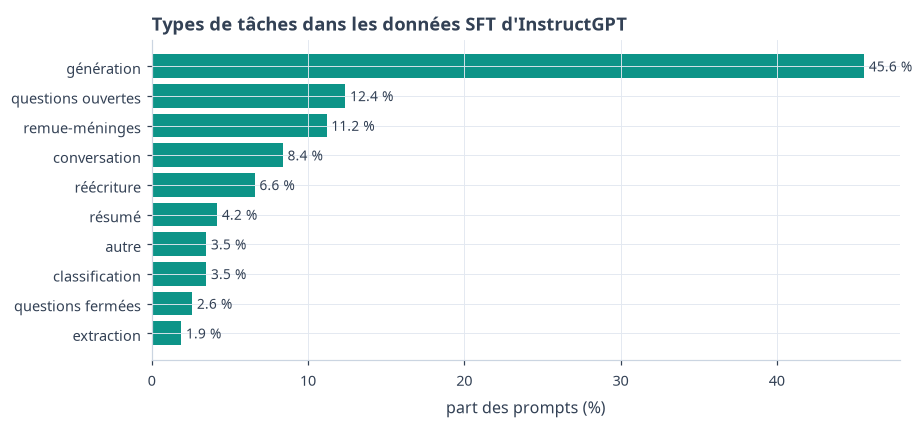

In [4]:
instruct_tasks = pd.Series({"génération": 45.6, "questions ouvertes": 12.4, "remue-méninges": 11.2,
                            "conversation": 8.4, "réécriture": 6.6, "résumé": 4.2, "classification": 3.5,
                            "autre": 3.5, "questions fermées": 2.6, "extraction": 1.9}).sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(instruct_tasks.index, instruct_tasks.values, color=TEAL)
annotate_bars(ax, "{:.1f} %")
ax.set_xlabel("part des prompts (%)"); ax.set_title("Types de tâches dans les données SFT d'InstructGPT")
plt.tight_layout(); plt.show()

**Le gabarit de conversation.** En pratique, chaque exemple est mis en forme avec des
**tokens spéciaux** qui délimitent les rôles. Voici le gabarit de Qwen2.5 :

In [5]:
tok_i, _ = llm.load(INSTRUCT_QWEN)
conv = [{"role": "user", "content": "Quelle est la capitale de l'Italie ?"},
        {"role": "assistant", "content": "La capitale de l'Italie est Rome."}]
templated = tok_i.apply_chat_template(conv, tokenize=False)
print(templated)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Quelle est la capitale de l'Italie ?<|im_end|>
<|im_start|>assistant
La capitale de l'Italie est Rome.<|im_end|>



**La perte du SFT.** On entraîne avec la même perte que le pré-entraînement (prédire le
token suivant), mais **seulement sur les tokens de la réponse** : les tokens du prompt
sont masqués, car on ne veut pas apprendre au modèle à générer les questions des
utilisateurs. Pour un exemple $(x, y)$ :
$$\mathcal L_{\text{SFT}} = -\sum_{t=1}^{|y|} \log p_\theta(y_t \mid x, y_{<t}).$$
La figure montre ce masque sur l'exemple, ainsi que la log-probabilité de chaque token de
la conversation sous le modèle de base et sous le modèle Instruct.

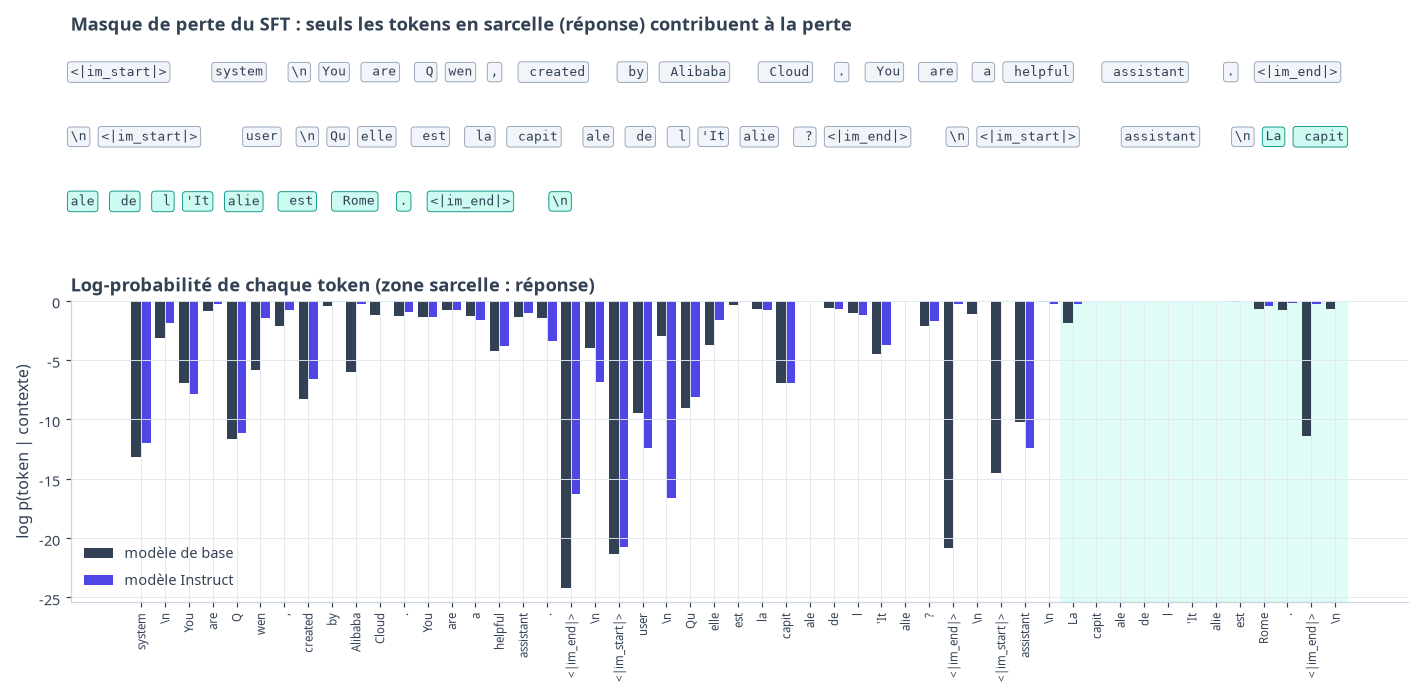

logprob moyenne sur la réponse : base -1.31, Instruct -0.11 nats/token


In [6]:
ids = tok_i(templated, return_tensors="pt")["input_ids"]
prompt_len = len(tok_i.apply_chat_template(conv[:1], tokenize=False, add_generation_prompt=True))
# position (en caractères) de chaque token pour savoir s'il appartient à la réponse
offsets = tok_i(templated, return_offsets_mapping=True)["offset_mapping"]
is_resp = np.array([s >= prompt_len for s, e in offsets])


def per_token_logprobs(model_id, ids):
    t, mdl = llm.load(model_id)
    with torch.no_grad():
        lp = torch.log_softmax(mdl(ids.to(mdl.device)).logits[0, :-1].float(), -1)
    return lp[torch.arange(ids.shape[1] - 1), ids[0, 1:].to(mdl.device)].cpu().numpy()


lp_base = per_token_logprobs(BASE_QWEN, ids)
lp_inst = per_token_logprobs(INSTRUCT_QWEN, ids)
toks = [tok_i.decode([i]).replace("\n", "\\n") for i in ids[0].tolist()]

fig, axes = plt.subplots(2, 1, figsize=(13, 6.4), gridspec_kw=dict(height_ratios=[1, 1.4]))
ax = axes[0]; ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
x, y = 0.0, 0.85
for t, r in zip(toks, is_resp):
    w = 0.0085 * max(len(t), 2) + 0.006
    if x + w > 1:
        x, y = 0.0, y - 0.3
    ax.text(x, y, t, fontsize=8.5, family="monospace", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc=LIGHT[TEAL] if r else LIGHT[GRAY], ec=TEAL if r else GRAY, lw=0.6))
    x += w
ax.set_title("Masque de perte du SFT : seuls les tokens en sarcelle (réponse) contribuent à la perte")
ax = axes[1]
pos = np.arange(1, len(toks))
ax.bar(pos - 0.2, lp_base, 0.4, color=SLATE, label="modèle de base")
ax.bar(pos + 0.2, lp_inst, 0.4, color=INDIGO, label="modèle Instruct")
ax.axvspan(np.argmax(is_resp) - 0.5, len(toks) - 0.5, color=LIGHT[TEAL], alpha=0.6, zorder=0)
ax.set_xticks(pos, toks[1:], rotation=90, fontsize=7.5)
ax.set_ylabel("log p(token | contexte)"); ax.legend(loc="lower left")
ax.set_title("Log-probabilité de chaque token (zone sarcelle : réponse)")
plt.tight_layout(); plt.show()
print(f"logprob moyenne sur la réponse : base {lp_base[is_resp[1:]].mean():.2f}, "
      f"Instruct {lp_inst[is_resp[1:]].mean():.2f} nats/token")

Le modèle Instruct prédit beaucoup mieux la **structure** de la conversation (tokens
spéciaux de fin de tour, début de réponse de l'assistant) : c'est exactement ce que le SFT
lui a appris. Sur le contenu factuel (« Rome »), les deux modèles sont proches : le
savoir vient du pré-entraînement.

**Le coût des démonstrations.** Rédiger une bonne réponse demande expertise et
jugement : environ 90 % des annotateurs d'InstructGPT avaient un diplôme universitaire,
plus d'un tiers un master, et une paire peut demander jusqu'à 30 minutes. À 10 \$ la
paire, les 13 000 démonstrations d'InstructGPT coûtent 130 000 \$, hors conception,
recrutement et contrôle qualité. Comparons quelques stratégies (chiffres du livre :
25 \$ pour une réponse rédigée, 3,50 \$ pour une comparaison chez Llama 2).

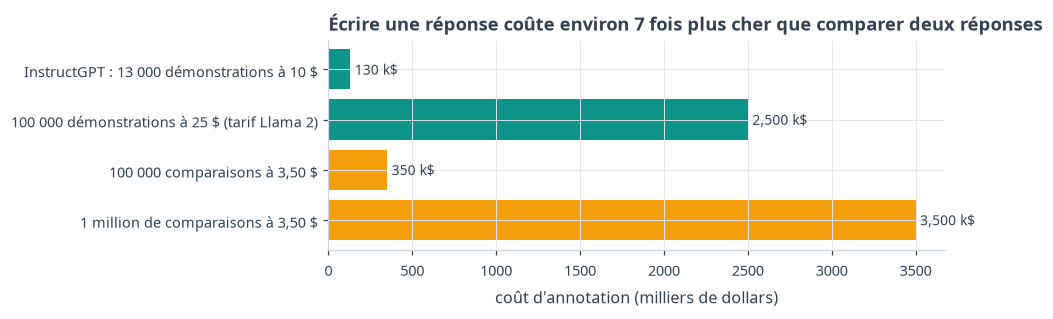

In [7]:
scenarios = pd.DataFrame([
    ("InstructGPT : 13 000 démonstrations à 10 $", 13_000 * 10),
    ("100 000 démonstrations à 25 $ (tarif Llama 2)", 100_000 * 25),
    ("100 000 comparaisons à 3,50 $", 100_000 * 3.5),
    ("1 million de comparaisons à 3,50 $", 1_000_000 * 3.5),
], columns=["stratégie", "coût ($)"]).set_index("stratégie")
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(scenarios.index, scenarios["coût ($)"] / 1e3, color=[TEAL, TEAL, AMBER, AMBER])
annotate_bars(ax, "{:,.0f} k$")
ax.invert_yaxis(); ax.set_xlabel("coût d'annotation (milliers de dollars)")
ax.set_title("Écrire une réponse coûte environ 7 fois plus cher que comparer deux réponses")
plt.tight_layout(); plt.show()

Les alternatives moins chères ont leurs biais : les 13 500 bénévoles de LAION
(OpenAssistant) étaient à 90 % des hommes ; DeepMind a extrait des dialogues du web avec
des heuristiques de format (« [A]: ... [B]: ... ») pour Gopher ; de plus en plus d'équipes
génèrent des démonstrations par IA (chapitre 8).

Ce format de dialogue illustre d'ailleurs que la capacité de converser est **déjà
latente** dans le modèle de base : il suffit de lui présenter un début de dialogue.

In [8]:
dialogue = ("A: Bonjour, peux-tu me donner un conseil pour mieux dormir ?\n"
            "B: Bien sûr. Essaie de te coucher et de te lever à heure fixe, même le week-end.\n"
            "A: Et pour me concentrer quand je travaille ?\nB:")
print("Modèle de base, dialogue en format A/B :")
print(short(llm.complete(dialogue, model_id=BASE_QWEN, max_new_tokens=40).split("\nA:")[0], 300))

Modèle de base, dialogue en format A/B :


Essaye de faire des exercices de concentration, comme des exercices de réflexion ou des exercices de concentration.


Dans ce format, le modèle de base produit une réplique qui joue le rôle de B, ce qui est
précisément ce que le SFT renforce et systématise.

> **À retenir.** Le SFT est un apprentissage supervisé classique sur des paires (prompt,
> réponse) mises en forme par un gabarit à tokens spéciaux, avec une perte calculée sur
> les seuls tokens de la réponse. Les démonstrations de qualité sont chères : c'est leur
> coût qui pousse vers les comparaisons et les données synthétiques.

## 3. Données de préférence : comparer plutôt que noter (section *Preference Finetuning*)

Les démonstrations apprennent au modèle **à** converser, pas **quelles** conversations
avoir. Faut-il répondre à une demande dangereuse ? À une question politique clivante ?
Les humains sont en désaccord, et un modèle trop censuré devient ennuyeux. Le
finetuning sur préférences vise à refléter « la préférence humaine », objectif ambitieux
qui suppose qu'une telle préférence existe et qu'on peut l'encoder.

**Noter ou comparer ?** Demander une note absolue (évaluation **ponctuelle**,
*pointwise*) donne des résultats instables : sur une échelle de 1 à 10, un annotateur
met 5 et un autre 7, et le même annotateur peut varier d'une fois à l'autre. Comparer deux
réponses est plus facile et plus fiable. Simulons-le : 40 réponses de qualité latente
$q_i$, 8 annotateurs ayant chacun leur **biais** (sévère ou indulgent) et leur
**échelle**, plus un bruit de jugement.

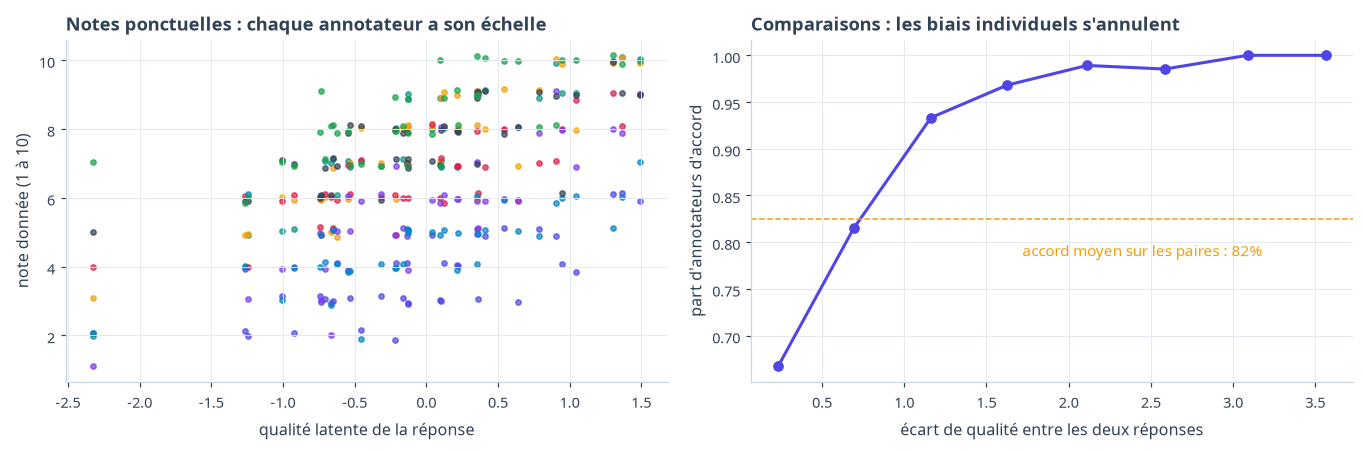

écart-type moyen des notes données à une même réponse : 1.7 point (notes extrêmes d'une même réponse : écart moyen de 5.0 points)


In [9]:
n_items, n_annot = 40, 8
q = rng.normal(0, 1, n_items)                       # qualité latente des réponses
bias = rng.normal(0, 1.0, n_annot)                  # sévérité propre à chaque annotateur
scale = rng.uniform(0.6, 1.4, n_annot)              # amplitude d'utilisation de l'échelle
perceived = q[None] * scale[:, None] + rng.normal(0, 0.5, (n_annot, n_items))
notes = np.clip(np.round(5.5 + 1.5 * (perceived + bias[:, None])), 1, 10)   # notes de 1 à 10

pairs = [(i, j) for i in range(n_items) for j in range(i + 1, n_items)]
agree, gaps = [], []
for i, j in pairs:
    prefs = perceived[:, i] > perceived[:, j]       # chaque annotateur compare avec sa propre perception
    p_major = max(prefs.mean(), 1 - prefs.mean())
    agree.append(p_major); gaps.append(abs(q[i] - q[j]))
agree, gaps = np.array(agree), np.array(gaps)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
for k in range(n_annot):
    ax.scatter(q, notes[k] + rng.uniform(-0.15, 0.15, n_items), s=12, alpha=0.7)
ax.set_xlabel("qualité latente de la réponse"); ax.set_ylabel("note donnée (1 à 10)")
ax.set_title("Notes ponctuelles : chaque annotateur a son échelle")
ax = axes[1]
bins = np.linspace(0, gaps.max(), 9)
idx = np.digitize(gaps, bins)
ax.plot([gaps[idx == b].mean() for b in range(1, len(bins)) if (idx == b).any()],
        [agree[idx == b].mean() for b in range(1, len(bins)) if (idx == b).any()], "o-", color=INDIGO)
ax.axhline(agree.mean(), color=AMBER, ls="--", lw=1)
ax.text(gaps.max() * 0.45, agree.mean() - 0.04, f"accord moyen sur les paires : {agree.mean():.0%}", color=AMBER)
ax.set_xlabel("écart de qualité entre les deux réponses"); ax.set_ylabel("part d'annotateurs d'accord")
ax.set_title("Comparaisons : les biais individuels s'annulent")
plt.tight_layout(); plt.show()
print(f"écart-type moyen des notes données à une même réponse : {notes.std(0).mean():.1f} point "
      f"(notes extrêmes d'une même réponse : écart moyen de {(notes.max(0) - notes.min(0)).mean():.1f} points)")

La sévérité d'un annotateur décale toutes ses notes mais **ne change pas ses
comparaisons** : la différence $q_i - q_j$ est invariante par translation. Le désaccord
restant vient des paires de qualité voisine. Le livre rapporte un accord inter-annotateurs
d'environ 73 % pour InstructGPT (sur 10 personnes, environ 7 classent pareil deux réponses).

Les données de comparaison ont la forme (prompt, réponse gagnante, réponse perdante).
Pour gagner du temps, un annotateur peut **classer** $K$ réponses d'un coup, ce qui
donne $\binom{K}{2}$ paires (3 réponses A > B > C donnent A > B, A > C, B > C). Même ainsi,
une comparaison prend 3 à 5 minutes (il faut vérifier les faits). Et les préférences
sont discutables : dans l'exemple du jeu HH-RLHF d'Anthropic cité par le livre, l'autrice
préfère la réponse étiquetée « perdante ».

> **À retenir.** Comparer est plus rapide, moins cher et plus cohérent que noter, car
> les biais d'échelle propres à chaque annotateur disparaissent dans la différence.

## 4. Le modèle de récompense de Bradley-Terry (section *Reward model*)

Comment obtenir un **score** à partir de simples comparaisons ? Le modèle de
Bradley-Terry suppose que la probabilité de préférer $y_w$ à $y_l$ dépend de la différence
de leurs récompenses :
$$P(y_w \succ y_l \mid x) = \sigma\big(r_\theta(x, y_w) - r_\theta(x, y_l)\big),
\qquad \sigma(z) = \frac{1}{1 + e^{-z}} .$$
Maximiser la vraisemblance des comparaisons revient à minimiser la perte utilisée par
InstructGPT :
$$\mathcal L(\theta) = -\,\mathbb E_{(x, y_w, y_l)}\Big[\log \sigma\big(s_w - s_l\big)\Big],
\qquad s_w = r_\theta(x, y_w),\ s_l = r_\theta(x, y_l).$$
Son gradient par rapport à l'écart $\Delta = s_w - s_l$ vaut $-(1 - \sigma(\Delta))$ :
il pousse à écarter les scores tant que le modèle n'est pas sûr de lui, puis s'éteint.
Notez qu'ajouter une constante à toutes les récompenses ne change rien : seules les
**différences** sont identifiables.

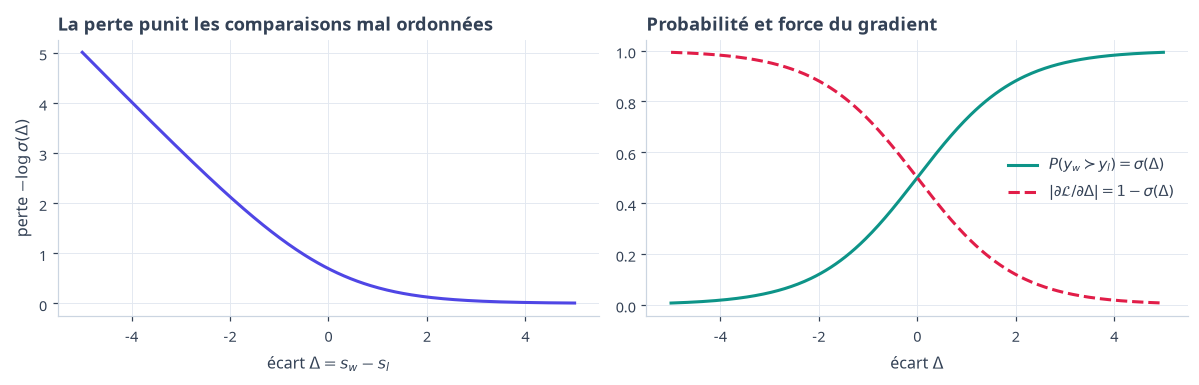

In [10]:
delta = np.linspace(-5, 5, 300)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(delta, -m.log_sigmoid(delta), color=INDIGO)
axes[0].set_xlabel(r"écart $\Delta = s_w - s_l$"); axes[0].set_ylabel(r"perte $-\log\sigma(\Delta)$")
axes[0].set_title("La perte punit les comparaisons mal ordonnées")
axes[1].plot(delta, m.sigmoid(delta), color=TEAL, label=r"$P(y_w \succ y_l) = \sigma(\Delta)$")
axes[1].plot(delta, 1 - m.sigmoid(delta), color=ROSE, ls="--", label=r"$|\partial \mathcal{L}/\partial\Delta| = 1-\sigma(\Delta)$")
axes[1].set_xlabel(r"écart $\Delta$"); axes[1].legend(); axes[1].set_title("Probabilité et force du gradient")
plt.tight_layout(); plt.show()

**Un jouet réaliste.** Décrivons chaque réponse par cinq caractéristiques normalisées :
pertinence, exactitude, clarté, longueur et assurance du ton. L'**utilité réelle** pour
l'utilisateur dépend des trois premières, et un ton trop péremptoire lui nuit plutôt
(il accompagne souvent des affirmations non vérifiées) :
$$u(y) = 1{,}2\,\text{pert.} + 1{,}5\,\text{exact.} + 0{,}6\,\text{clarté} - 0{,}5\,\text{assurance}.$$
Mais les annotateurs, humains, ont deux biais connus : ils préfèrent les réponses
**longues** et **assurées**. Leur préférence latente est donc
$$h(y) = u(y) + 0{,}5\,\text{longueur} + 1{,}1\,\text{assurance},$$
et chaque comparaison est tirée selon $P(a \succ b) = \sigma(h(a) - h(b))$. On ajuste un
modèle de récompense linéaire $r_\theta(y) = \theta^\top y$ par descente de gradient sur la
perte de Bradley-Terry (`m.fit_linear_reward`).

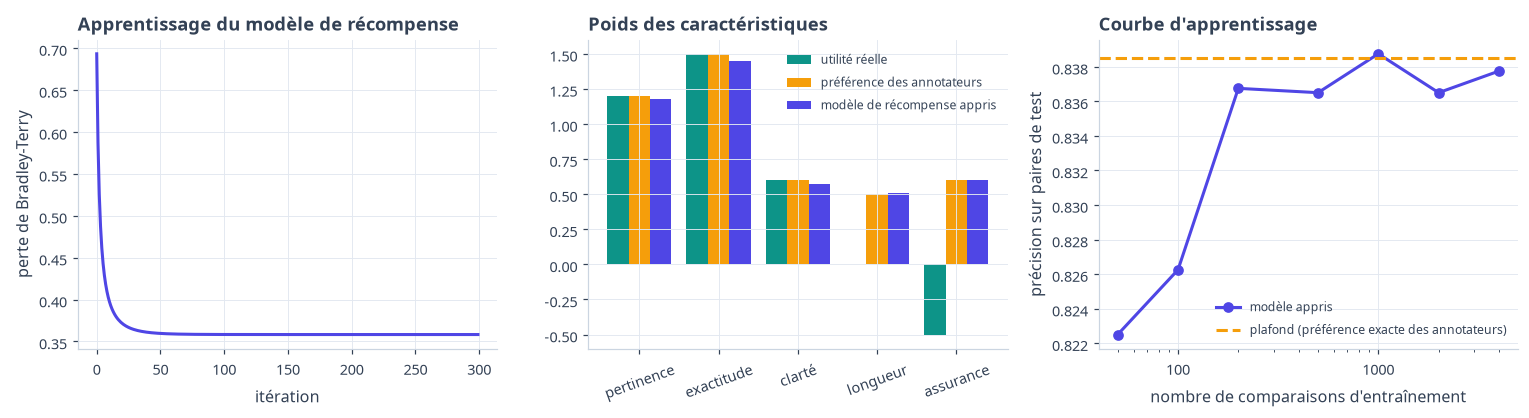

précision sur paires de test : 83.8% (plafond 83.9%) ; accord attendu entre deux annotateurs : 78%


In [11]:
FEATS = ["pertinence", "exactitude", "clarté", "longueur", "assurance"]
w_util = np.array([1.2, 1.5, 0.6, 0.0, -0.5])
w_human = w_util + np.array([0, 0, 0, 0.5, 1.1])


def make_comparisons(n, rng):
    A, B = rng.normal(size=(2, n, 5))
    a_wins = rng.random(n) < m.sigmoid((A - B) @ w_human)
    Xw = np.where(a_wins[:, None], A, B); Xl = np.where(a_wins[:, None], B, A)
    return Xw, Xl


Xw, Xl = make_comparisons(4000, rng)
Xw_te, Xl_te = make_comparisons(4000, np.random.default_rng(99))
theta, hist = m.fit_linear_reward(Xw, Xl, lr=0.5, epochs=300)
acc = ((Xw_te - Xl_te) @ theta > 0).mean()
ceiling = ((Xw_te - Xl_te) @ w_human > 0).mean()
p_h = m.sigmoid((Xw_te - Xl_te) @ w_human)
agreement = np.mean(p_h ** 2 + (1 - p_h) ** 2)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].plot(hist, color=INDIGO); axes[0].set_xlabel("itération"); axes[0].set_ylabel("perte de Bradley-Terry")
axes[0].set_title("Apprentissage du modèle de récompense")
x = np.arange(5)
axes[1].bar(x - 0.27, w_util, 0.27, color=TEAL, label="utilité réelle")
axes[1].bar(x, w_human, 0.27, color=AMBER, label="préférence des annotateurs")
axes[1].bar(x + 0.27, theta, 0.27, color=INDIGO, label="modèle de récompense appris")
axes[1].set_xticks(x, FEATS, rotation=20); axes[1].legend(fontsize=8); axes[1].set_title("Poids des caractéristiques")
sizes = [50, 100, 200, 500, 1000, 2000, 4000]
accs = []
for n in sizes:
    th, _ = m.fit_linear_reward(Xw[:n], Xl[:n], epochs=300)
    accs.append(((Xw_te - Xl_te) @ th > 0).mean())
axes[2].semilogx(sizes, accs, "o-", color=INDIGO, label="modèle appris")
axes[2].axhline(ceiling, color=AMBER, ls="--", label="plafond (préférence exacte des annotateurs)")
axes[2].set_xlabel("nombre de comparaisons d'entraînement"); axes[2].set_ylabel("précision sur paires de test")
m.plain_log_axis(axes[2]); axes[2].legend(fontsize=8, loc="lower right")
axes[2].set_title("Courbe d'apprentissage")
plt.tight_layout(); plt.show()
print(f"précision sur paires de test : {acc:.1%} (plafond {ceiling:.1%}) ; "
      f"accord attendu entre deux annotateurs : {agreement:.0%}")

Trois enseignements :

1. le modèle de récompense retrouve fidèlement la **préférence des annotateurs**,
   y compris leurs biais : il récompense la longueur (inutile à l'utilisateur) et
   l'assurance (qui lui nuit). Un modèle de récompense apprend ce que les annotateurs **disent**
   préférer, pas ce qui est réellement utile ;
2. la précision plafonne bien en dessous de 100 % : les comparaisons sont bruitées
   (l'accord attendu entre deux annotateurs simulés est du même ordre que les 73 %
   d'InstructGPT), et aucun modèle ne peut prédire un jugement aléatoire ;
3. quelques centaines de comparaisons suffisent pour 5 caractéristiques ; un vrai modèle
   de récompense, initialisé sur un LLM (souvent le modèle SFT lui-même) avec des
   milliards de paramètres, en demande des centaines de milliers.

Le livre note que le modèle de récompense est souvent aussi gros que le modèle à juger,
bien que juger soit sans doute plus facile que générer (chapitre 3, l'IA comme juge).

> **À retenir.** Le modèle de récompense transforme des comparaisons en score grâce à la
> perte $-\log\sigma(s_w - s_l)$. Il hérite de tous les biais des annotateurs.

## 5. Optimiser contre la récompense : RLHF et DPO (section *Finetuning using the reward model*)

Avec le modèle de récompense, on entraîne le modèle SFT (la **politique** $\pi_\theta$) à
produire des réponses bien notées, sur des prompts tirés d'une distribution réaliste.
L'algorithme historique est PPO (OpenAI, 2017). L'objectif optimisé contient un terme
crucial, une pénalité de divergence de Kullback-Leibler par rapport au modèle SFT
$\pi_{\text{ref}}$ :
$$\max_{\pi}\ \mathbb E_{x,\ y \sim \pi(\cdot\mid x)}\big[r(x, y)\big]
- \beta\, \mathrm{KL}\big(\pi(\cdot \mid x)\,\|\,\pi_{\text{ref}}(\cdot \mid x)\big).$$
Sans elle, la politique trouverait vite les failles du modèle de récompense
(*reward hacking*) et produirait des textes dégénérés. Pour une distribution discrète,
cet objectif a une **solution exacte** (un calcul variationnel classique) :
$$\pi^\star(y \mid x) = \frac{1}{Z(x)}\,\pi_{\text{ref}}(y \mid x)\,\exp\!\big(r(x, y)/\beta\big).$$
Petit $\beta$ : on suit aveuglément la récompense ; grand $\beta$ : on reste collé au
modèle SFT. Illustrons-le sur six réponses candidates à un même prompt, dont une
« astucieuse » que le modèle de récompense surévalue (longue, très assurée, mais
inexacte).

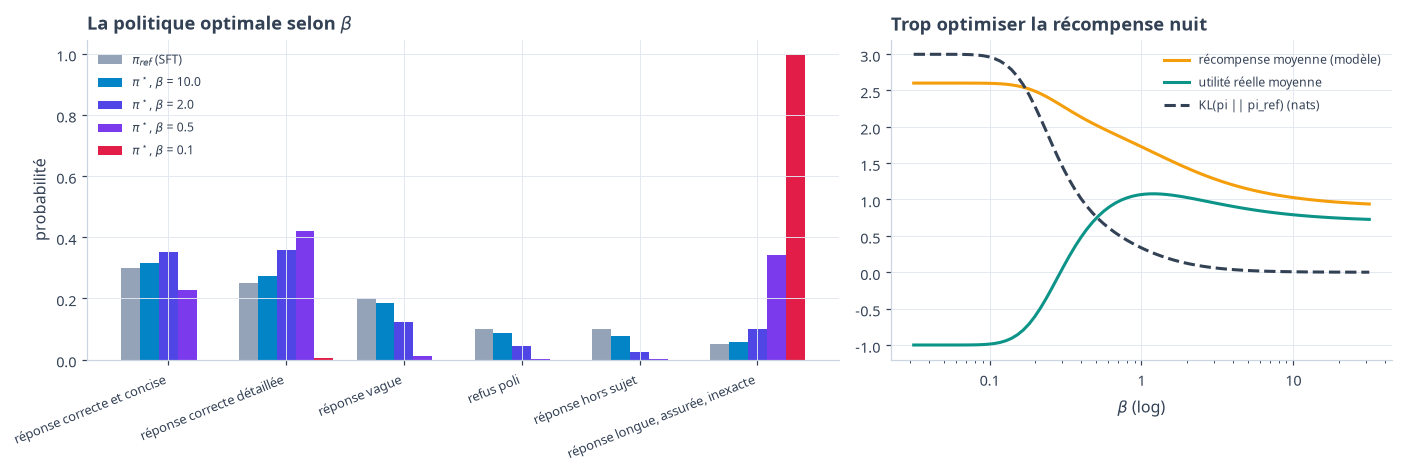

In [12]:
cands = ["réponse correcte et concise", "réponse correcte détaillée", "réponse vague", "refus poli",
         "réponse hors sujet", "réponse longue, assurée, inexacte"]
p_ref = np.array([0.30, 0.25, 0.20, 0.10, 0.10, 0.05])
r_rm = np.array([1.5, 1.9, 0.2, -0.5, -1.5, 2.6])      # score du modèle de récompense (biaisé)
u_true = np.array([1.6, 1.7, 0.1, -0.3, -1.5, -1.0])   # utilité réelle
betas = [10.0, 2.0, 0.5, 0.1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
x = np.arange(len(cands)); wbar = 0.16
ax.bar(x - 2 * wbar, p_ref, wbar, color=GRAY, label=r"$\pi_{ref}$ (SFT)")
for k, (b, c) in enumerate(zip(betas, [SKY, INDIGO, VIOLET, ROSE])):
    ax.bar(x + (k - 1) * wbar, m.kl_regularized_policy(p_ref, r_rm, b), wbar, color=c, label=fr"$\pi^\star$, $\beta$ = {b}")
ax.set_xticks(x, cands, rotation=22, ha="right", fontsize=8.5); ax.set_ylabel("probabilité")
ax.legend(fontsize=8); ax.set_title(r"La politique optimale selon $\beta$")
ax = axes[1]
bgrid = np.logspace(-1.5, 1.5, 80)
pis = np.array([m.kl_regularized_policy(p_ref, r_rm, b) for b in bgrid])
ax.semilogx(bgrid, pis @ r_rm, color=AMBER, label="récompense moyenne (modèle)")
ax.semilogx(bgrid, pis @ u_true, color=TEAL, label="utilité réelle moyenne")
kl = (pis * np.log(pis / p_ref)).sum(1)
ax.semilogx(bgrid, kl, color=SLATE, ls="--", label="KL(pi || pi_ref) (nats)")
ax.set_xlabel(r"$\beta$ (log)"); ax.legend(fontsize=8); m.plain_log_axis(ax)
ax.set_title("Trop optimiser la récompense nuit")
plt.tight_layout(); plt.show()

Quand $\beta$ diminue, la politique s'éloigne du modèle SFT (KL croissante) et la
récompense **mesurée** augmente sans cesse ; l'utilité **réelle**, elle, passe par un
maximum puis s'effondre quand la politique se concentre sur la réponse astucieuse. C'est
la loi de Goodhart appliquée au RLHF : quand une mesure devient un objectif, elle cesse
d'être une bonne mesure. Le coefficient $\beta$ règle ce compromis.

**DPO : se passer du modèle de récompense explicite.** En inversant la formule de
$\pi^\star$, la récompense s'écrit $r(x, y) = \beta \log\frac{\pi^\star(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \beta\log Z(x)$.
En injectant cette expression dans la perte de Bradley-Terry, $Z(x)$ disparaît (c'est
une différence) et l'on obtient une perte qui porte **directement sur la politique**
(Rafailov et al., 2023) :
$$\mathcal L_{\text{DPO}} = -\,\mathbb E\Big[\log\sigma\Big(\beta\log\frac{\pi_\theta(y_w)}{\pi_{\text{ref}}(y_w)}
- \beta\log\frac{\pi_\theta(y_l)}{\pi_{\text{ref}}(y_l)}\Big)\Big].$$
Vérifions numériquement que DPO retrouve la solution du RLHF : on génère des comparaisons
entre nos six réponses selon le modèle de Bradley-Terry de récompense `r_rm`, puis on
optimise les logits d'une politique par descente de gradient sur $\mathcal L_{\text{DPO}}$.
Pour une politique $\pi_\theta = \operatorname{softmax}(\theta)$, le gradient est simple :
$-(1-\sigma(z))\,\beta\,(e_w - e_l)$, la normalisation se simplifiant dans la différence.

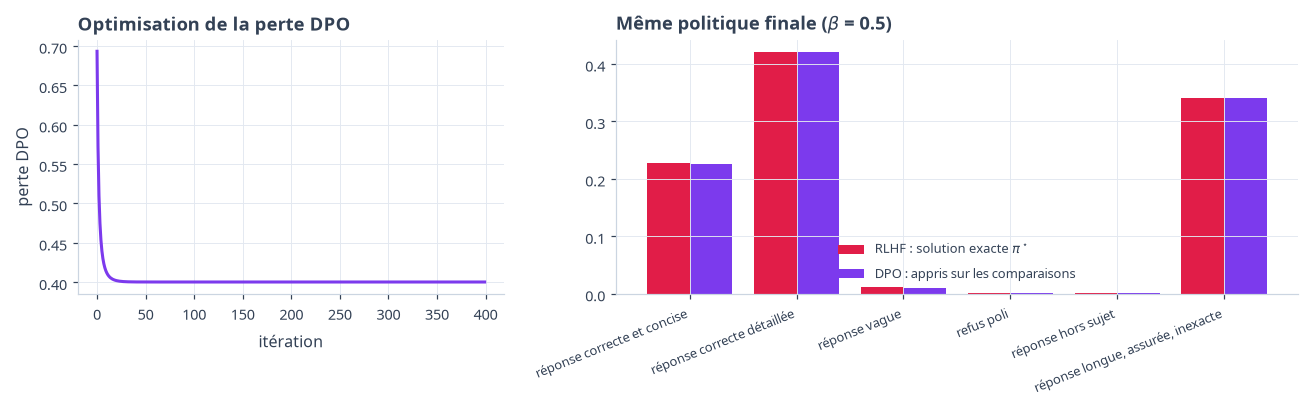

écart max. entre politiques RLHF et DPO : 0.001


In [13]:
beta = 0.5
rd = np.random.default_rng(5)
n_pairs = 20000
ia, ib = rd.integers(0, 6, (2, n_pairs))
keep = ia != ib
ia, ib = ia[keep], ib[keep]
a_wins = rd.random(ia.size) < m.sigmoid(r_rm[ia] - r_rm[ib])
yw, yl = np.where(a_wins, ia, ib), np.where(a_wins, ib, ia)
logits = np.log(p_ref).copy()                       # on part de la politique de référence
dpo_hist = []
for it in range(400):
    logp = logits - np.log(np.exp(logits - logits.max()).sum()) - logits.max()
    z = beta * ((logp[yw] - np.log(p_ref[yw])) - (logp[yl] - np.log(p_ref[yl])))
    dpo_hist.append(-m.log_sigmoid(z).mean())
    g = -(1 - m.sigmoid(z)) * beta
    grad = np.zeros(6)
    np.add.at(grad, yw, g); np.add.at(grad, yl, -g)
    logits -= 2.0 * grad / yw.size * 6
pi_dpo = llm.softmax(logits)
pi_rlhf = m.kl_regularized_policy(p_ref, r_rm, beta)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 1.6]))
axes[0].plot(dpo_hist, color=VIOLET); axes[0].set_xlabel("itération"); axes[0].set_ylabel("perte DPO")
axes[0].set_title("Optimisation de la perte DPO")
axes[1].bar(x - 0.2, pi_rlhf, 0.4, color=ROSE, label=r"RLHF : solution exacte $\pi^\star$")
axes[1].bar(x + 0.2, pi_dpo, 0.4, color=VIOLET, label="DPO : appris sur les comparaisons")
axes[1].set_xticks(x, cands, rotation=22, ha="right", fontsize=8.5); axes[1].legend(fontsize=8.5)
axes[1].set_title(fr"Même politique finale ($\beta$ = {beta})")
plt.tight_layout(); plt.show()
print(f"écart max. entre politiques RLHF et DPO : {np.abs(pi_rlhf - pi_dpo).max():.3f}")

DPO atteint la même politique que le RLHF régularisé, sans entraîner de modèle de
récompense ni lancer de boucle d'apprentissage par renforcement : d'où son adoption
(Meta est passé du RLHF pour Llama 2 à DPO pour Llama 3, pour réduire la complexité). Le
livre présente surtout RLHF, plus complexe mais plus flexible. Les deux améliorent
empiriquement les modèles par rapport au SFT seul, sans que l'on sache encore bien
expliquer pourquoi.

> **À retenir.** RLHF maximise la récompense sous une contrainte de proximité (KL) avec le
> modèle SFT, dont la solution est $\pi^\star \propto \pi_{\text{ref}}\, e^{r/\beta}$. DPO
> optimise directement cette solution à partir des comparaisons. Dans les deux cas, trop
> optimiser une récompense imparfaite dégrade l'utilité réelle.

## 6. Best-of-N et sur-optimisation

Certaines entreprises (Stitch Fix, Grab, selon le livre) se passent du RL : elles
génèrent $N$ réponses et gardent celle que le modèle de récompense note le mieux. C'est la
stratégie **best-of-N**, une forme de *test time compute* (cours 4). Elle a un coût en
divergence bien connu : la distribution best-of-N s'écarte de la politique de départ
d'environ $\log N - \frac{N-1}{N}$ nats.

Reprenons notre jouet : des réponses candidates aux caractéristiques aléatoires, notées
par le modèle de récompense appris $\theta$ (biaisé vers la longueur et l'assurance). Une
hypothèse réaliste : la plupart des réponses ont un ton normal, mais quelques-unes sont
extrêmement péremptoires (l'assurance suit une loi à **queue lourde**, Student à 3 degrés
de liberté). Comparons la sélection par le modèle de récompense et une sélection idéale
par l'utilité réelle (un « oracle »).

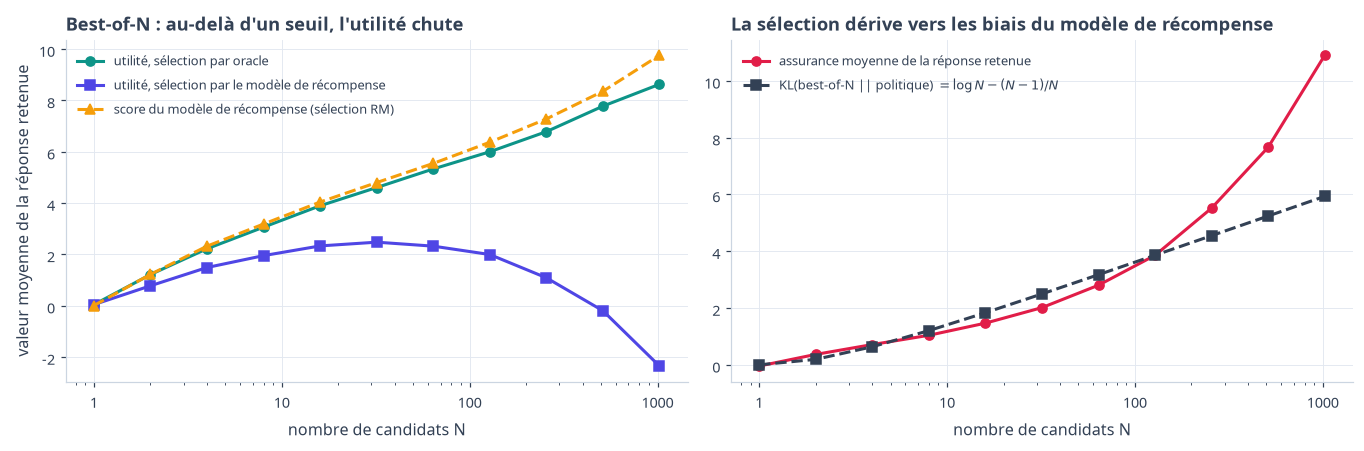

In [14]:
Ns = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024]
rb = np.random.default_rng(11)
res = []
for N in Ns:
    cand = rb.normal(size=(2000, N, 5))
    cand[..., 4] = rb.standard_t(3, size=(2000, N))          # assurance : queue lourde
    rm_score, util = cand @ theta, cand @ w_util
    pick = rm_score.argmax(1)
    chosen = cand[np.arange(2000), pick]
    res.append(dict(N=N, score_rm=rm_score.max(1).mean(), utilite_rm=(chosen @ w_util).mean(),
                    utilite_oracle=util.max(1).mean(), assurance=chosen[:, 4].mean(),
                    kl=np.log(N) - (N - 1) / N))
res = pd.DataFrame(res)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.semilogx(res.N, res.utilite_oracle, "o-", color=TEAL, label="utilité, sélection par oracle")
ax.semilogx(res.N, res.utilite_rm, "s-", color=INDIGO, label="utilité, sélection par le modèle de récompense")
ax.semilogx(res.N, res.score_rm, "^--", color=AMBER, label="score du modèle de récompense (sélection RM)")
ax.set_xlabel("nombre de candidats N"); ax.set_ylabel("valeur moyenne de la réponse retenue")
m.plain_log_axis(ax); ax.legend(fontsize=8.5); ax.set_title("Best-of-N : au-delà d'un seuil, l'utilité chute")
ax = axes[1]
ax.semilogx(res.N, res.assurance, "o-", color=ROSE, label="assurance moyenne de la réponse retenue")
ax.semilogx(res.N, res.kl, "s--", color=SLATE, label=r"KL(best-of-N || politique) $= \log N - (N-1)/N$")
ax.set_xlabel("nombre de candidats N"); m.plain_log_axis(ax); ax.legend(fontsize=8.5)
ax.set_title("La sélection dérive vers les biais du modèle de récompense")
plt.tight_layout(); plt.show()

Pour de petits $N$, sélectionner par le modèle de récompense améliore nettement
l'utilité réelle. Puis l'écart avec l'oracle se creuse, et au-delà de quelques dizaines de
candidats l'utilité **diminue** alors que le score continue de monter : avec beaucoup de
candidats, le gagnant est de plus en plus souvent une réponse extrêmement péremptoire,
que le modèle de récompense adore et que l'utilisateur subit. C'est la sur-optimisation
(loi de Goodhart) décrite par Gao et al. (2022). Le livre rapporte une observation d'OpenAI dans le même esprit : au-delà
d'environ 400 échantillons, les performances baissent, sans doute parce que la chance de
trouver une sortie qui « trompe » le vérificateur augmente. Un bon vérificateur reste
néanmoins très précieux : OpenAI a mesuré qu'il apportait autant qu'un modèle 30 fois
plus gros sur des problèmes de mathématiques.

> **À retenir.** Best-of-N exploite le modèle de récompense sans RL, au prix de $N$
> générations. Plus on sélectionne fort, plus les défauts du juge comptent : c'est la
> même sur-optimisation que dans le RLHF.

## Synthèse

- **Pourquoi.** Un modèle pré-entraîné complète du texte et reflète le web ; le
  post-entraînement (2 % du calcul pour InstructGPT) le rend utile et sûr.
- **SFT.** Clonage de comportement sur des paires (prompt, réponse) mises en forme par un
  gabarit, perte calculée sur la seule réponse. Démonstrations coûteuses (10 à 25 \$ la
  paire).
- **Préférences.** Comparer est moins cher (environ 3,50 \$) et plus cohérent que noter ;
  l'accord inter-annotateurs reste limité (environ 73 %).
- **Modèle de récompense.** Bradley-Terry : $P(y_w \succ y_l) = \sigma(s_w - s_l)$, perte
  $-\log\sigma(s_w - s_l)$. Il apprend les préférences **et les biais** des annotateurs.
- **RLHF et DPO.** Maximiser la récompense sous contrainte KL ; solution
  $\pi^\star \propto \pi_{\text{ref}}e^{r/\beta}$, que DPO atteint directement.
- **Best-of-N.** Sélection par le modèle de récompense sans RL ; attention à la
  sur-optimisation (loi de Goodhart).

**Liens.** Le chapitre 3 traite de l'IA comme juge (proche du modèle de récompense) ; le
chapitre 7 détaille le finetuning (SFT, LoRA) ; le chapitre 8 la création de données de
démonstration et de préférence ; le cours 4 exploite best-of-N et le vote majoritaire sur
un vrai modèle.

In [15]:
llm.free_gpu()